In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydhn
from pydhn.fluids import Fluid
from pydhn.soils import Soil
from pydhn.solving import SimpleStep, Scheduler

In [9]:
# ---------------------------------------------------------------------------
# Simulation parameters
# ---------------------------------------------------------------------------
STEPSIZE       = 600          # time step [s]  (10 min)
NUM_SIM_STEPS  = 1008         # 7 days × 144 steps/day
T_AMBIENT_C    = 10.0         # ambient / ground temperature [°C]

In [10]:
# ---------------------------------------------------------------------------
# File paths
# ---------------------------------------------------------------------------
PIPES_FILE = "pipes.csv"
NODES_FILE = "nodes.csv"
DEMAND_PROFILE_FILE = "../../data/demand_profile.csv"
POWER_PROSUMER_PROFILE = "prosumer_production_profile.csv"

# ---------------------------------------------------------------------------
# Load input data
# ---------------------------------------------------------------------------
pipe_data = pd.read_csv(PIPES_FILE)
node_data = pd.read_csv(NODES_FILE)

demand_profile_data = pd.read_csv(DEMAND_PROFILE_FILE)
demand_profile_data = demand_profile_data[:NUM_SIM_STEPS]

production_profile_data = pd.read_csv(POWER_PROSUMER_PROFILE)
production_profile_data = production_profile_data[:NUM_SIM_STEPS]

time_sim   = demand_profile_data["timestep"].values * STEPSIZE      # [s]

# PROSUMER ENERGY BALANCE
consumption_prosumer = demand_profile_data["Q_W"]                   # [W]
production_prosumer  = production_profile_data["Q_W"]               # [W]
self_prosumer = np.minimum(consumption_prosumer, production_prosumer)

# Demand side: heat requested from network
heat_consumption_prosumer = (
    consumption_prosumer - self_prosumer)                           # [W]
# Production side: heat injected into network
heat_production_prosumer = (
    production_prosumer - self_prosumer)                            # [W]


MDOT_BYPASS_KGS = 1.77 / 3600                                       # [kg/s], bypass mass flow

print(f"Loaded topological data from {PIPES_FILE} "
      f"--- dynamic simulation of {len(demand_profile_data)} time steps.")

Loaded topological data from pipes.csv --- dynamic simulation of 1008 time steps.


In [11]:
# ---------------------------------------------------------------------------
# Fluid and soil
# ---------------------------------------------------------------------------
# Properties taken from first pipe row (homogeneous network assumption)
p0 = pipe_data.iloc[0]

fluid = Fluid(
    name       = "Water",
    isconstant = True,
    cp         = p0["fluid_cp_JkgK"],
    mu         = p0["fluid_mu_Pas"],
    rho        = p0["fluid_rho_kgm3"],
    k          = p0["fluid_lambda_WmK"],
)

soil = Soil(
    k    = p0["soil_lambda_WmK"],
    temp = p0["T_ground_degC"],
)

# ---------------------------------------------------------------------------
# Built network
# ---------------------------------------------------------------------------
net = pydhn.Network()

# Add nodes
prosumer_junction_map = {}

for idx, row in node_data.iterrows():
    name      = row["node_id"]
    node_type = row["node_type"]
    X, Y      = row["x_m"], row["y_m"]

    name_s = f"{name}_s"
    name_r = f"{name}_r"

    net.add_node(name=name_s, x=X, y=-Y)
    net.add_node(name=name_r, x=X, y=-Y)

    # Add substations
    if node_type == "substation":
        delta_t = float(row["delta_T_nom_K"])

        net.add_consumer(
            name              = name,
            start_node        = name_s,
            end_node          = name_r,
            control_type      = "energy",
            setpoint_type_hx  = "delta_t",
            setpoint_value_hx = -delta_t,
            design_delta_t    = abs(delta_t),
            t_out_min_hx      = 10,
            mass_flow_min     = MDOT_BYPASS_KGS,
            stepsize          = STEPSIZE,
        )

    # Add prosumer
    if node_type == "prosumer":
        delta_t     = float(row["delta_T_nom_K"])

        # --- CONSUMPTION side ---
        net.add_consumer(
            name              = name,
            start_node        = name_s,
            end_node          = name_r,
            control_type      = "energy",
            setpoint_type_hx  = "delta_t",
            setpoint_value_hx = -delta_t,
            design_delta_t    = abs(delta_t),
            t_out_min_hx      = 10,
            stepsize          = STEPSIZE,
        )

        # --- PRODUCTION side ---
        name_prod_s = f"{name}_prod_s"
        name_prod_r = f"{name}_prod_r"
        net.add_node(name=name_prod_s, x=X, y=-Y)
        net.add_node(name=name_prod_r, x=X, y=-Y)

        t_prosumer_out = float(row["T_supply_set_degC"])
        mdot_prosumer  = production_prosumer / (fluid.cp * delta_t)

        net.add_producer(
            name                = f"{name}_prod",
            start_node          = name_prod_r,
            end_node            = name_prod_s,
            setpoint_type_hyd   = "mass_flow",
            setpoint_value_hyd  = mdot_prosumer.max(),
            setpoint_type_hx    = "t_out",
            setpoint_value_hx   = t_prosumer_out,
            stepsize            = STEPSIZE,
        )

        conn = pipe_data[
            (pipe_data["from_node"] == name) | (pipe_data["to_node"] == name)
        ]
        if len(conn) == 0:
            raise ValueError(f"No connceted pipe found for prosumer {name}")
        prosumer_junction_map[name] = conn.iloc[0]


    # Add central generators
    elif node_type == "source":
        t_supply    = float(row["T_supply_set_degC"])
        p_ref       = float(row["p_ref_bar"])

        setpoint_type_hyd  = "pressure"
        setpoint_value_hyd = - p_ref * 1e5

        net.add_producer(
            name                = name,
            start_node          = name_r,
            end_node            = name_s,
            setpoint_type_hyd   = setpoint_type_hyd,
            setpoint_value_hyd  = setpoint_value_hyd,
            setpoint_type_hx    = "t_out",
            setpoint_value_hx   = t_supply,
            stepsize            = STEPSIZE,
        )

# Add pipes
for _, row in pipe_data.iterrows():
    name = row["pipe_id"]
    frm  = row["from_node"]
    to   = row["to_node"]

    common = dict(
        # --- geometry ---
        diameter                = row["d_inner_m"],                 # carrier pipe inner diameter [m]
        length                  = row["length_m"],                  # pipe length [m]
        internal_pipe_thickness = row["wall_m"],                    # carrier pipe wall thickness [m]
        insulation_thickness    = row["insulation_thickness_m"],    # insulation thickness (0 if none) [m]
        casing_thickness        = row["casing_thickness_m"],        # casing wall thickness (0 if none) [m]
        # --- hydraulic ---
        roughness               = row["roughness_mm"],              # absolute roughness [mm]
        # --- thermal: insulation ---
        k_insulation            = row["PUR_lambda_WmK"],            # PUR thermal conductivity [W/(m·K)]
        # --- thermal: carrier pipe ---
        k_internal_pipe         = row["carrier_lambda_WmK"],        # carrier-pipe thermal conductivity [W/(m·K)]
        rho_wall                = row["carrier_rho_kgm3"],          # carrier-pipe density [kg/m³]
        cp_wall                 = row["carrier_cp_JkgK"],           # carrier-pipe specific heat [J/(kg·K)]
        # --- thermal: casing ---
        k_casing                = row["HDPE_lambda_WmK"],           # HDPE thermal conductivity [W/(m·K)]
        # --- burial ---
        depth                   = row["burial_depth_m"],            # burial depth [m]
        h_ext                   = row["h_ext_Wm2K"],                # external heat transfer coeff. [W/(m²·K)]
        # --- simulation ---
        stepsize                = STEPSIZE,                         # time step [s]
    )

    # Supply pipe
    net.add_lagrangian_pipe(
        name       = f"{name}_s",
        start_node = f"{frm}_s",
        end_node   = f"{to}_s",
        line       = "supply",
        **common,
    )

    # Return pipe
    net.add_lagrangian_pipe(
        name       = f"{name}_r",
        start_node = f"{to}_r",
        end_node   = f"{frm}_r",
        line       = "return",
        **common,
    )

# Add duplicated pipes for PRODUCER nodes
for name, conn_row in prosumer_junction_map.items():
    junction_id = conn_row["to_node"] if conn_row["from_node"] == name else conn_row["from_node"]
    pid = f"{conn_row['pipe_id']}_prod"

    common_dup = dict(
        diameter                = conn_row["d_inner_m"],
        length                  = conn_row["length_m"],
        internal_pipe_thickness = conn_row["wall_m"],
        insulation_thickness    = conn_row["insulation_thickness_m"],
        casing_thickness        = conn_row["casing_thickness_m"],
        roughness               = conn_row["roughness_mm"],
        k_insulation            = conn_row["PUR_lambda_WmK"],
        k_internal_pipe         = conn_row["carrier_lambda_WmK"],
        rho_wall                = conn_row["carrier_rho_kgm3"],
        cp_wall                 = conn_row["carrier_cp_JkgK"],
        k_casing                = conn_row["HDPE_lambda_WmK"],
        depth                   = conn_row["burial_depth_m"],
        h_ext                   = conn_row["h_ext_Wm2K"],
        stepsize                = STEPSIZE,
    )

    net.add_lagrangian_pipe(
        name=f"{pid}_s", start_node=f"{name}_prod_s", end_node=f"{junction_id}_s",
        line="supply", **common_dup,
    )
    net.add_lagrangian_pipe(
        name=f"{pid}_r", start_node=f"{junction_id}_r", end_node=f"{name}_prod_r",
        line="return", **common_dup,
    )

print(f"--- {len(prosumer_junction_map)} prosumer production branches connected. ---")

print("--- Network setup complete. ---")

--- 10 prosumer production branches connected. ---
--- Network setup complete. ---


In [12]:
# ---------------------------------------------------------------------------
# Schedules
# ---------------------------------------------------------------------------
consumer_names      = []
prosumer_cons_names = []   # consumer
prosumer_prod_names = []   # producer

heat_demand_schedule   = pd.DataFrame()   # standard substations + consumption side of prosumer
prosumer_mdot_schedule = pd.DataFrame()   # production side of prosumer

for i in node_data.index:
    row       = node_data.loc[i]
    name      = row["node_id"]
    node_type = row["node_type"]

    if node_type == "substation":
        consumer_names.append(name)
        heat_demand_schedule[name] = - demand_profile_data["Q_W"]

    if node_type == "prosumer":
        delta_t_i = abs(float(row["delta_T_nom_K"]))

        # --- CONSUMER side ---
        prosumer_cons_names.append(name)
        heat_demand_schedule[name] = - heat_consumption_prosumer

        # --- PRODUCER side ---
        prod_name = f"{name}_prod"
        prosumer_prod_names.append(prod_name)

        mdot_prod = heat_production_prosumer / (delta_t_i * fluid.cp)   # [kg/s]
        mdot_prod = np.maximum(mdot_prod, MDOT_BYPASS_KGS)              # physical floor

        prosumer_mdot_schedule[prod_name] = mdot_prod

schedules = {
    "heat_demand":        heat_demand_schedule,     # substation + consumer side of prosumer
    "setpoint_value_hyd": prosumer_mdot_schedule,   # producer side of prosumer
}

print(f"Schedules built: {len(consumer_names)} consumers × {NUM_SIM_STEPS} steps + "
      f"{len(prosumer_cons_names)} prosumer (consumption side) + "
      f"{len(prosumer_prod_names)} prosumer (production side) × {NUM_SIM_STEPS} steps")

Schedules built: 90 consumers × 1008 steps + 10 prosumer (consumption side) + 10 prosumer (production side) × 1008 steps


In [13]:
# ---------------------------------------------------------------------------
# Pre-heating (network initialization)
# ---------------------------------------------------------------------------
print("--- Initializing Network (Pre-heating for stability) ---")

INIT_STEPS = 144  # 1 day

init_demand = pd.DataFrame(
    np.tile(heat_demand_schedule.iloc[0].values, (INIT_STEPS, 1)),
    columns=heat_demand_schedule.columns,
)

init_mdot_prosumer = pd.DataFrame(
    np.tile(prosumer_mdot_schedule.iloc[0].values, (INIT_STEPS, 1)),
    columns=prosumer_mdot_schedule.columns,
)

init_schedules = {
    "heat_demand": init_demand,
    "setpoint_value_hyd": init_mdot_prosumer,
}

base_loop_init = SimpleStep(
    hydraulic_sim_kwargs={"error_threshold": 1e2, "verbose": False},
    thermal_sim_kwargs={"error_threshold": 1e-6, "verbose": False},
    with_thermal=True,
)

scheduler_init = Scheduler(
    base_loop=base_loop_init,
    schedules=init_schedules,
    steps=INIT_STEPS,
)

import time
t0 = time.perf_counter()
_  = scheduler_init.execute(net=net, fluid=fluid, soil=soil)
print(f"Pre-heating done in {time.perf_counter()-t0:.2f} s. "
      f"({INIT_STEPS} steps = {INIT_STEPS*STEPSIZE/3600:.1f} h.)")

--- Initializing Network (Pre-heating for stability) ---
Scheduler started
Step 0:
Loop started


C:\Users\sara.ferrero\PycharmProjects\dhn-benchmark\.venv\Lib\site-packages\pydhn\utilities\matrices.py:187: FutureWarning: incidence_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  return nx.incidence_matrix(


Loop completed
Step 1:
Loop started
Loop completed
Step 2:
Loop started
Loop completed
Step 3:
Loop started
Loop completed
Step 4:
Loop started
Loop completed
Step 5:
Loop started
Loop completed
Step 6:
Loop started
Loop completed
Step 7:
Loop started
Loop completed
Step 8:
Loop started
Loop completed
Step 9:
Loop started
Loop completed
Step 10:
Loop started
Loop completed
Step 11:
Loop started
Loop completed
Step 12:
Loop started
Loop completed
Step 13:
Loop started
Loop completed
Step 14:
Loop started
Loop completed
Step 15:
Loop started
Loop completed
Step 16:
Loop started
Loop completed
Step 17:
Loop started
Loop completed
Step 18:
Loop started
Loop completed
Step 19:
Loop started
Loop completed
Step 20:
Loop started
Loop completed
Step 21:
Loop started
Loop completed
Step 22:
Loop started
Loop completed
Step 23:
Loop started
Loop completed
Step 24:
Loop started
Loop completed
Step 25:
Loop started
Loop completed
Step 26:
Loop started
Loop completed
Step 27:
Loop started
Loop compl

In [14]:
# ---------------------------------------------------------------------------
# Full simulation
# ---------------------------------------------------------------------------
print("--- Running with Scheduler (Full Simulation) ---")

base_loop_scheduler = SimpleStep(
    hydraulic_sim_kwargs={"error_threshold": 1e2, "verbose": False},
    thermal_sim_kwargs  ={"error_threshold": 1e-6, "verbose": False},
    with_thermal=True,
)

scheduler = Scheduler(
    base_loop=base_loop_scheduler,
    schedules=schedules,
    steps=NUM_SIM_STEPS,
)

t0 = time.perf_counter()
results = scheduler.execute(net=net, fluid=fluid, soil=soil)
sim_time = time.perf_counter() - t0

print(f"Simulation complete.")
print(f"Average simulation time: {sim_time:.2f} s.")

--- Running with Scheduler (Full Simulation) ---
Scheduler started
Step 0:
Loop started
Loop completed
Step 1:
Loop started
Loop completed
Step 2:
Loop started
Loop completed
Step 3:
Loop started
Loop completed
Step 4:
Loop started
Loop completed
Step 5:
Loop started
Loop completed
Step 6:
Loop started
Loop completed
Step 7:
Loop started
Loop completed
Step 8:
Loop started
Loop completed
Step 9:
Loop started
Loop completed
Step 10:
Loop started
Loop completed
Step 11:
Loop started
Loop completed
Step 12:
Loop started
Loop completed
Step 13:
Loop started
Loop completed
Step 14:
Loop started
Loop completed
Step 15:
Loop started
Loop completed
Step 16:
Loop started
Loop completed
Step 17:
Loop started
Loop completed
Step 18:
Loop started
Loop completed
Step 19:
Loop started
Loop completed
Step 20:
Loop started
Loop completed
Step 21:
Loop started
Loop completed
Step 22:
Loop started
Loop completed
Step 23:
Loop started
Loop completed
Step 24:
Loop started
Loop completed
Step 25:
Loop star

In [15]:
# ---------------------------------------------------------------------------
# Extracted variables
# ---------------------------------------------------------------------------
res = results.to_dataframes()

substation_names = node_data[node_data["node_type"] == "substation"]["node_id"].tolist()
producer_names   = node_data[node_data["node_type"] == "prosumer"]["node_id"].tolist()
source_name      = node_data[node_data["node_type"] == "source"]["node_id"].tolist()
pipe_names       = pipe_data["pipe_id"].tolist()

# ── ETS (standard consumer) ───────────────────────────────────────────────────
T_sub_s  = res["nodes"]["temperature"][[f"{n}_s" for n in substation_names]]
T_sub_r  = res["nodes"]["temperature"][[f"{n}_r" for n in substation_names]]
mdot_sub = res["edges"]["mass_flow"][substation_names]
Q_sub_W  = -res["edges"]["delta_q"][substation_names] / (STEPSIZE / 3600)  # [W]
dT_sub   = pd.DataFrame(
    T_sub_s.values - T_sub_r.values,
    columns=substation_names,
)  # [K]

# ── PROSUMER ─────────────────────────────────────────────────────────────────
# Consumption side
T_pro_cons_s  = res["nodes"]["temperature"][[f"{n}_s" for n in prosumer_cons_names]]
T_pro_cons_r  = res["nodes"]["temperature"][[f"{n}_r" for n in prosumer_cons_names]]
mdot_pro_cons = res["edges"]["mass_flow"][prosumer_cons_names]
Q_pro_cons_W  = -res["edges"]["delta_q"][prosumer_cons_names] / (STEPSIZE / 3600)  # [W]
dT_pro_cons   = pd.DataFrame(
    T_pro_cons_s.values - T_pro_cons_r.values,
    columns=prosumer_cons_names,
)  # [K]

# Production side
T_pro_prod_s  = res["nodes"]["temperature"][[f"{n}_s" for n in prosumer_prod_names]]
T_pro_prod_r  = res["nodes"]["temperature"][[f"{n}_r" for n in prosumer_prod_names]]
mdot_pro_prod = res["edges"]["mass_flow"][prosumer_prod_names]
Q_pro_prod_W  = res["edges"]["delta_q"][prosumer_prod_names] / (STEPSIZE / 3600)  # [W]
dT_pro_prod   = pd.DataFrame(
    T_pro_prod_s.values - T_pro_prod_r.values,
    columns=prosumer_prod_names,
)  # [K]

# ── PRODUCER ─────────────────────────────────────────────────────────────────
T_src_s  = res["nodes"]["temperature"][[f"{n}_s" for n in source_name]]
T_src_r  = res["nodes"]["temperature"][[f"{n}_r" for n in source_name]]
mdot_src = res["edges"]["mass_flow"][source_name]
Q_src_W  = res["edges"]["delta_q"][source_name] / (STEPSIZE / 3600)  # [W]

# ── PIPE ─────────────────────────────────────────────────────────────────────
dp_pipe_s   = res["edges"]["delta_p"][[f"{n}_s"   for n in pipe_names]]   # [Pa]
dp_pipe_r   = res["edges"]["delta_p"][[f"{n}_r"   for n in pipe_names]]   # [Pa]
mdot_pipe_s = res["edges"]["mass_flow"][[f"{n}_s" for n in pipe_names]]   # [kg/s]
mdot_pipe_r = res["edges"]["mass_flow"][[f"{n}_r" for n in pipe_names]]   # [kg/s]
T_pipe_s    = res["edges"]["temperature"][[f"{n}_s" for n in pipe_names]] # [°C]
T_pipe_r    = res["edges"]["temperature"][[f"{n}_r" for n in pipe_names]] # [°C]
Q_loss_pipe_s = res["edges"]["delta_q"][[f"{n}_s" for n in pipe_names]] / (STEPSIZE / 3600)  # [W]
Q_loss_pipe_r = res["edges"]["delta_q"][[f"{n}_r" for n in pipe_names]] / (STEPSIZE / 3600)  # [W]

# ── PIPE (allacci duplicati del ramo PRODUCER dei prosumer) ─────────────────
prosumer_prod_pipe_names = [f"{conn_row['pipe_id']}_prod"
                             for conn_row in prosumer_junction_map.values()]

dp_pipe_prod_s   = res["edges"]["delta_p"][[f"{n}_s"   for n in prosumer_prod_pipe_names]]
dp_pipe_prod_r   = res["edges"]["delta_p"][[f"{n}_r"   for n in prosumer_prod_pipe_names]]
mdot_pipe_prod_s = res["edges"]["mass_flow"][[f"{n}_s" for n in prosumer_prod_pipe_names]]
mdot_pipe_prod_r = res["edges"]["mass_flow"][[f"{n}_r" for n in prosumer_prod_pipe_names]]
T_pipe_prod_s    = res["edges"]["temperature"][[f"{n}_s" for n in prosumer_prod_pipe_names]]
T_pipe_prod_r    = res["edges"]["temperature"][[f"{n}_r" for n in prosumer_prod_pipe_names]]
Q_loss_pipe_prod_s = res["edges"]["delta_q"][[f"{n}_s" for n in prosumer_prod_pipe_names]] / (STEPSIZE / 3600)
Q_loss_pipe_prod_r = res["edges"]["delta_q"][[f"{n}_r" for n in prosumer_prod_pipe_names]] / (STEPSIZE / 3600)

# ── JUNCTION NODES ───────────────────────────────────────────────────────────
exclude_nodes = (
    {f"{n}_s" for n in substation_names} |
    {f"{n}_r" for n in substation_names} |
    {f"{n}_s" for n in prosumer_cons_names} |
    {f"{n}_r" for n in prosumer_cons_names} |
    {f"{n}_s" for n in prosumer_prod_names} |
    {f"{n}_r" for n in prosumer_prod_names} |
    {f"{n}_s" for n in source_name} |
    {f"{n}_r" for n in source_name}
)
junction_cols = [c for c in res["nodes"]["temperature"].columns
                 if c not in exclude_nodes]
T_junction = res["nodes"]["temperature"][junction_cols]

# ── ENERGY BALANCE ───────────────────────────────────────────────────────────
SKIP = 144   # steps to skip (1 day initialization)

# Source — backup generator
Q_src_prod_MWh = Q_src_W.iloc[SKIP:].sum().sum() * (STEPSIZE / 3600) / 1e6
# Consumer — consumption (standard)
Q_con_cons_MWh = Q_sub_W.iloc[SKIP:].sum().sum() * (STEPSIZE / 3600) / 1e6
# Prosumer — consumption side
Q_pro_cons_MWh = Q_pro_cons_W.iloc[SKIP:].sum().sum() * (STEPSIZE / 3600) / 1e6
# Prosumer — production side
Q_pro_prod_MWh = Q_pro_prod_W.iloc[SKIP:].sum().sum() * (STEPSIZE / 3600) / 1e6

Q_pro_net_MWh = Q_pro_prod_MWh - Q_pro_cons_MWh

# Losses
Q_loss_MWh = -(
    Q_loss_pipe_s.iloc[SKIP:].sum().sum()
    + Q_loss_pipe_r.iloc[SKIP:].sum().sum()
    + Q_loss_pipe_prod_s.iloc[SKIP:].sum().sum()
    + Q_loss_pipe_prod_r.iloc[SKIP:].sum().sum()
) * (STEPSIZE / 3600) / 1e6

# Net balance
Q_prod_MWh  = Q_src_prod_MWh + Q_pro_prod_MWh
Q_cons_MWh  = Q_con_cons_MWh + Q_pro_cons_MWh
eta_network =  Q_cons_MWh / Q_prod_MWh

print("=" * 55)
print("ENERGY BALANCE")
print("=" * 55)
print(f"  Source   — production:      {Q_src_prod_MWh:.3f} MWh")
print(f"  Consumer — consumption:     {Q_con_cons_MWh:.3f} MWh")
print(f"  Prosumer — consumption:     {Q_pro_cons_MWh:.3f} MWh")
print(f"  Prosumer — production:      {Q_pro_prod_MWh:.3f} MWh")
print(f"  Pipe losses:                {Q_loss_MWh:.3f} MWh")
print(f"  Network η:                  {eta_network*100:.1f} %")
print("=" * 55)

# ---------------------------------------------------------------------------
# Save results
# ---------------------------------------------------------------------------
import os

results_dir = os.path.join("..", "..", "results")
os.makedirs(results_dir, exist_ok=True)

output_path = os.path.join(results_dir, "5G_M_M_BASE_results.xlsx")

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:

    # ── ETS ──────────────────────────────────────────────────────────────────
    T_sub_s.iloc[SKIP:].to_excel(writer,  sheet_name="sub_T_supply_degC")
    T_sub_r.iloc[SKIP:].to_excel(writer,  sheet_name="sub_T_return_degC")
    dT_sub.iloc[SKIP:].to_excel(writer,   sheet_name="sub_dT_K")
    mdot_sub.iloc[SKIP:].to_excel(writer, sheet_name="sub_mdot_kgs")
    Q_sub_W.iloc[SKIP:].to_excel(writer,  sheet_name="sub_Q_W")

    # ── PROSUMER — consumption ───────────────────────────────────────────────────
    T_pro_cons_s.iloc[SKIP:].to_excel(writer,  sheet_name="pro_cons_T_supply_degC")
    T_pro_cons_r.iloc[SKIP:].to_excel(writer,  sheet_name="pro_cons_T_return_degC")
    dT_pro_cons.iloc[SKIP:].to_excel(writer,   sheet_name="pro_cons_dT_K")
    mdot_pro_cons.iloc[SKIP:].to_excel(writer, sheet_name="pro_cons_mdot_kgs")
    Q_pro_cons_W.iloc[SKIP:].to_excel(writer,  sheet_name="pro_cons_Q_W")

    # ── PROSUMER — production ────────────────────────────────────────────────────
    T_pro_prod_s.iloc[SKIP:].to_excel(writer,  sheet_name="pro_prod_T_supply_degC")
    T_pro_prod_r.iloc[SKIP:].to_excel(writer,  sheet_name="pro_prod_T_return_degC")
    dT_pro_prod.iloc[SKIP:].to_excel(writer,   sheet_name="pro_prod_dT_K")
    mdot_pro_prod.iloc[SKIP:].to_excel(writer, sheet_name="pro_prod_mdot_kgs")
    Q_pro_prod_W.iloc[SKIP:].to_excel(writer,  sheet_name="pro_prod_Q_W")

    # ── PRODUCER (backup generator) ──────────────────────────────────────────────
    T_src_s.iloc[SKIP:].to_excel(writer,  sheet_name="src_T_supply_degC")
    T_src_r.iloc[SKIP:].to_excel(writer,  sheet_name="src_T_return_degC")
    mdot_src.iloc[SKIP:].to_excel(writer, sheet_name="src_mdot_kgs")
    Q_src_W.iloc[SKIP:].to_excel(writer,  sheet_name="src_Q_W")

    # ── PIPE ─────────────────────────────────────────────────────────────────────
    dp_pipe_s.iloc[SKIP:].to_excel(writer,       sheet_name="pipe_s_dp_Pa")
    dp_pipe_r.iloc[SKIP:].to_excel(writer,       sheet_name="pipe_r_dp_Pa")
    mdot_pipe_s.iloc[SKIP:].to_excel(writer,     sheet_name="pipe_s_mdot_kgs")
    T_pipe_s.iloc[SKIP:].to_excel(writer,        sheet_name="pipe_s_T_out_degC")
    T_pipe_r.iloc[SKIP:].to_excel(writer,        sheet_name="pipe_r_T_out_degC")
    Q_loss_pipe_s.iloc[SKIP:].to_excel(writer,   sheet_name="pipe_s_Qloss_W")
    Q_loss_pipe_r.iloc[SKIP:].to_excel(writer,   sheet_name="pipe_r_Qloss_W")

    # ── PIPE (double conncetion for prosumer) ────────────────────────────────────
    mdot_pipe_prod_s.iloc[SKIP:].to_excel(writer,   sheet_name="pipe_prod_s_mdot_kgs")
    Q_loss_pipe_prod_s.iloc[SKIP:].to_excel(writer, sheet_name="pipe_prod_s_Qloss_W")
    Q_loss_pipe_prod_r.iloc[SKIP:].to_excel(writer, sheet_name="pipe_prod_r_Qloss_W")

    # ── JUNCTION NODES ───────────────────────────────────────────────────────────
    T_junction.iloc[SKIP:].to_excel(writer, sheet_name="junction_T_degC")

    # ── ENERGY BALANCE ───────────────────────────────────────────────────────────
    pd.DataFrame({
        "Q_src_production_MWh":        [Q_src_prod_MWh],
        "Q_consumer_consumption_MWh":  [Q_con_cons_MWh],
        "Q_prosumer_consumption_MWh":  [Q_pro_cons_MWh],
        "Q_prosumer_production_MWh":   [Q_pro_prod_MWh],
        "Q_produced_MWh":              [Q_prod_MWh],
        "Q_consumed_MWh":              [Q_cons_MWh],
        "Q_losses_MWh":                [Q_loss_MWh],
        "eta_network":                 [eta_network],
    }).to_excel(writer, sheet_name="energy_balance")

print(f"Results saved in: {os.path.abspath(output_path)}")

ENERGY BALANCE
  Source   — production:      232.394 MWh
  Consumer — consumption:     571.923 MWh
  Prosumer — consumption:     0.016 MWh
  Prosumer — production:      364.338 MWh
  Pipe losses:                24.836 MWh
  Network η:                  95.8 %
Results saved in: C:\Users\sara.ferrero\PycharmProjects\dhn-benchmark\archetypes_generation\results\5G_M_M_BASE_results.xlsx


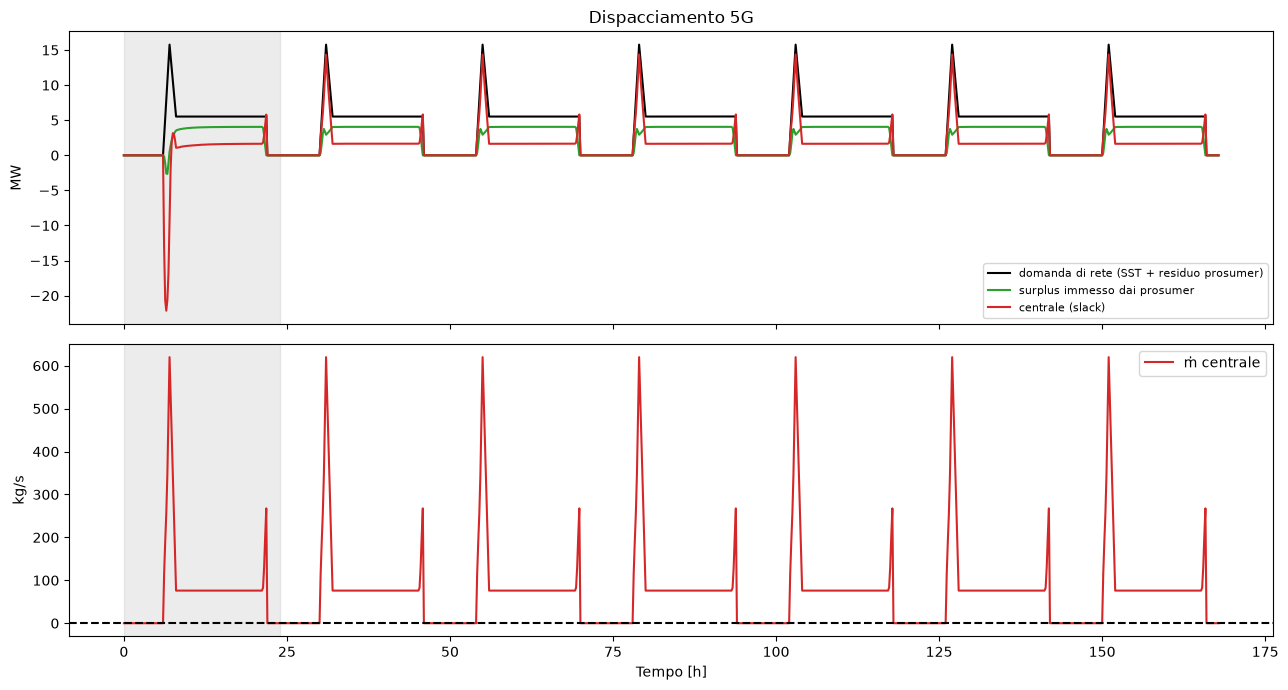

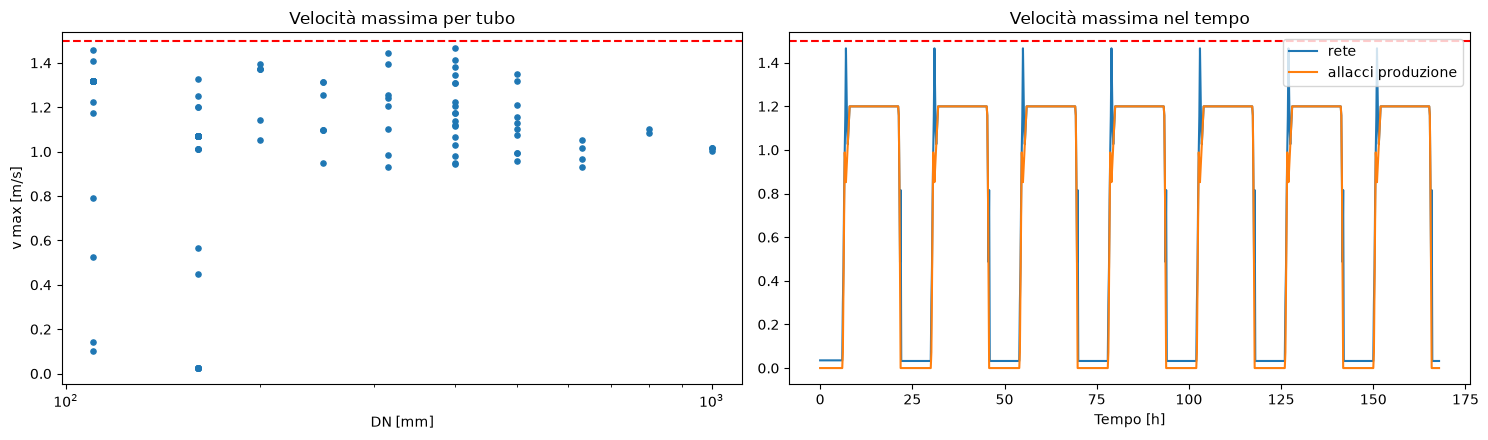

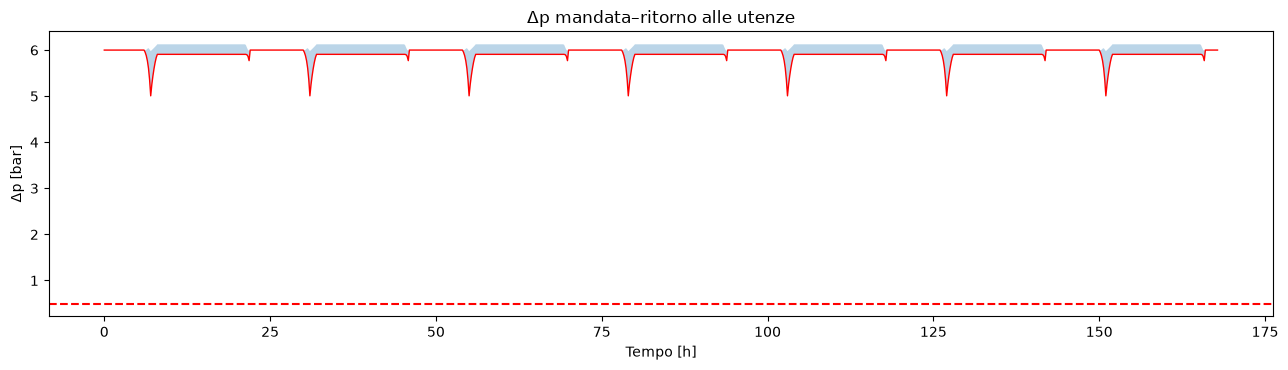

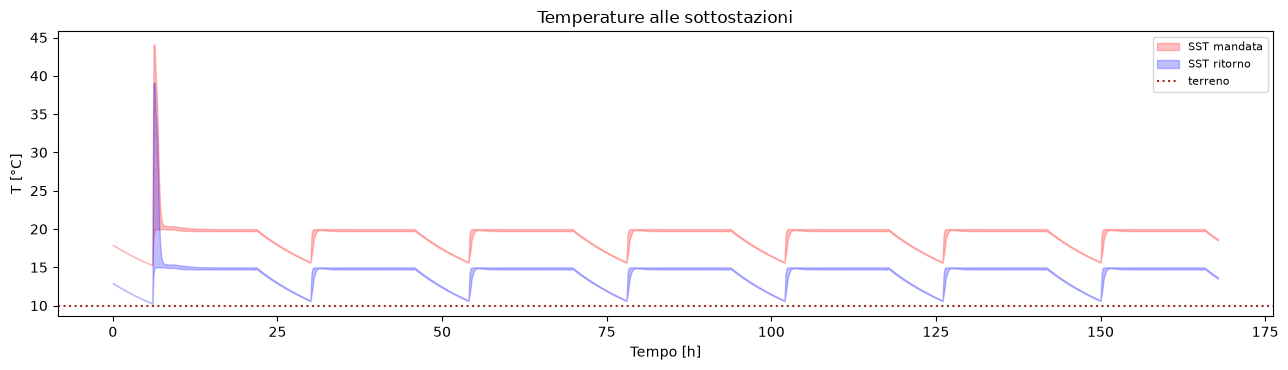

CHECKLIST DI FATTIBILITÀ — 5G_M_M_BASE
✅ Centrale mai negativa in riscaldamento (min 0.0 kg/s)
✅ Quota prosumer al base load ≈ 70 % (71.0 %)
✅ v ≤ 1.5 m/s nella rete (max 1.47)
✅ v ≤ 1.5 m/s negli allacci di produzione (max 1.20)
✅ Δp utenze ≥ 0.5 bar in riscaldamento (min 5.01)
❌ Copertura domanda ≥ 99 % (min 18.1 %)
✅ Residuo bilancio energetico < 2 % (-0.01 %)


In [16]:
# =====================================================================
# VERIFICA TERMO-IDRAULICA 5G_M_M_BASE  (eseguire dopo la cella 7)
# =====================================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt

V_LIM, DP_MIN = 1.5, 0.5                       # [m/s] v_max 5G, [bar]
n     = len(res["nodes"]["temperature"])
t_h   = np.arange(n) * STEPSIZE / 3600
hour  = pd.Series(demand_profile_data["label"].values[:n]).str[4:6].astype(int).values
after = np.arange(n) >= SKIP
heat  = after & (hour >= 6) & (hour < 22)
base  = after & (hour >= 8) & (hour < 21)
cen   = source_name[0]

# ---- 1. Dispacciamento: centrale vs prosumer ------------------------
Q_cen  = Q_src_W[cen].values
Q_inj  = Q_pro_prod_W.sum(axis=1).values
Q_dem  = Q_sub_W.sum(axis=1).values + Q_pro_cons_W.sum(axis=1).values
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax[0].plot(t_h, Q_dem/1e6, "k", lw=1.5, label="domanda di rete (SST + residuo prosumer)")
ax[0].plot(t_h, Q_inj/1e6, color="tab:green", label="surplus immesso dai prosumer")
ax[0].plot(t_h, Q_cen/1e6, color="tab:red", label="centrale (slack)")
ax[0].set_ylabel("MW"); ax[0].legend(fontsize=8); ax[0].set_title("Dispacciamento 5G")
ax[1].plot(t_h, mdot_src[cen].values, color="tab:red", label="ṁ centrale")
ax[1].axhline(0, color="k", ls="--"); ax[1].set_ylabel("kg/s"); ax[1].set_xlabel("Tempo [h]"); ax[1].legend()
for a in ax: a.axvspan(0, SKIP*STEPSIZE/3600, color="grey", alpha=0.15)
plt.tight_layout(); plt.show()
share = Q_inj[base].sum() / (Q_inj[base].sum() + Q_cen[base].sum())

# ---- 2. Velocità (rete + allacci duplicati della produzione) --------
rho = float(pipe_data["fluid_rho_kgm3"].iloc[0])
A   = np.pi * pipe_data["d_inner_m"].values**2 / 4
V   = mdot_pipe_s.abs().values / (rho * A)
d_prod = np.array([r["d_inner_m"] for r in prosumer_junction_map.values()])
V_prod = mdot_pipe_prod_s.abs().values / (rho * np.pi * d_prod**2 / 4)
vmax = V[after].max(0)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].scatter(pipe_data["DN_mm"], vmax, s=14); ax[0].axhline(V_LIM, color="r", ls="--")
ax[0].set_xscale("log"); ax[0].set_xlabel("DN [mm]"); ax[0].set_ylabel("v max [m/s]")
ax[0].set_title("Velocità massima per tubo")
ax[1].plot(t_h, V.max(1), label="rete"); ax[1].plot(t_h, V_prod.max(1), label="allacci produzione")
ax[1].axhline(V_LIM, color="r", ls="--"); ax[1].set_xlabel("Tempo [h]"); ax[1].legend()
ax[1].set_title("Velocità massima nel tempo")
plt.tight_layout(); plt.show()

# ---- 3. Pressione differenziale alle utenze --------------------------
P = res["nodes"].get("pressure")
users = substation_names + prosumer_cons_names
dpS = (P[[f"{u}_s" for u in users]].values - P[[f"{u}_r" for u in users]].values) / 1e5
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.fill_between(t_h, dpS.min(1), dpS.max(1), alpha=.3); ax.plot(t_h, dpS.min(1), "r", lw=1)
ax.axhline(DP_MIN, color="r", ls="--"); ax.set_ylabel("Δp [bar]"); ax.set_xlabel("Tempo [h]")
ax.set_title("Δp mandata–ritorno alle utenze"); plt.tight_layout(); plt.show()

# ---- 4. Termica: temperature e copertura ------------------------------
req_sub = schedules["heat_demand"].abs()[substation_names].values[:n]
req_pro = schedules["heat_demand"].abs()[prosumer_cons_names].values[:n]
cov = np.r_[Q_sub_W.values[after].sum(0) / req_sub[after].sum(0),
            Q_pro_cons_W.values[after].sum(0) / np.maximum(req_pro[after].sum(0), 1e-9)]
Ql  = -(Q_loss_pipe_s.sum(1) + Q_loss_pipe_r.sum(1)
        + Q_loss_pipe_prod_s.sum(1) + Q_loss_pipe_prod_r.sum(1)).values
res_pct = ((Q_cen + Q_inj) - Q_dem - Ql)[after].sum() / (Q_cen + Q_inj)[after].sum() * 100
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.fill_between(t_h, T_sub_s.min(1), T_sub_s.max(1), color="r", alpha=.25, label="SST mandata")
ax.fill_between(t_h, T_sub_r.min(1), T_sub_r.max(1), color="b", alpha=.25, label="SST ritorno")
ax.axhline(float(pipe_data["T_ground_degC"].iloc[0]), color="brown", ls=":", label="terreno")
ax.set_ylabel("T [°C]"); ax.set_xlabel("Tempo [h]"); ax.legend(fontsize=8)
ax.set_title("Temperature alle sottostazioni"); plt.tight_layout(); plt.show()

# ---- 5. Checklist -----------------------------------------------------
checks = {
    f"Centrale mai negativa in riscaldamento (min {mdot_src[cen].values[heat].min():.1f} kg/s)": mdot_src[cen].values[heat].min() >= -1e-3,
    f"Quota prosumer al base load ≈ 70 % ({share*100:.1f} %)":       abs(share - 0.70) < 0.05,
    f"v ≤ {V_LIM} m/s nella rete (max {vmax.max():.2f})":             vmax.max() <= V_LIM,
    f"v ≤ {V_LIM} m/s negli allacci di produzione (max {V_prod[after].max():.2f})": V_prod[after].max() <= V_LIM,
    f"Δp utenze ≥ {DP_MIN} bar in riscaldamento (min {dpS[heat].min():.2f})": dpS[heat].min() >= DP_MIN,
    f"Copertura domanda ≥ 99 % (min {cov.min()*100:.1f} %)":          cov.min() >= 0.99,
    f"Residuo bilancio energetico < 2 % ({res_pct:.2f} %)":           abs(res_pct) < 2,
}
print("=" * 70 + "\nCHECKLIST DI FATTIBILITÀ — 5G_M_M_BASE\n" + "=" * 70)
for k, ok in checks.items(): print(("✅ " if ok else "❌ ") + k)